# 02. 급지별 가격지수·시장국면·양방향 Granger 통합 분석

## 통일된 주 분석
- 전체 완결 월(2017-11~2026-09), 2018년 구별 **산술평균 ㎡당 가격**으로 K-means **k=4**, 군집 고정.
- 단지·면적 유형 고정효과 월지수로 거래 구성 차이를 줄인다. 유형은 시군구·번지·단지명·전용면적(소수 2자리)로 식별한다. 동일 주택의 반복매매 지수는 아니다.
- 구별 모형: 유형·월별 평균 로그 ㎡당 가격 = 유형 고정효과 + 월 고정효과 + 오차. 유형·월 관측을 동일 가중하며 2개월 이상 거래된 유형을 사용한다. 전체 월 연결성을 검증한다. 층·내부 상태·재건축 기대·노후화 등 시간에 따라 변하는 차이는 남는다.
- 구별 월 효과를 지수화하여 각 구의 2018년 월평균=100으로 맞춘 뒤, 급지 안에서 구를 동일 비중으로 평균한다. 전체 기간을 이용해 추정하는 사후 지수이며 실시간 예측 성능이 아니다.
- 고정유형 지수의 월별 상승률로 검정한다. 3개월 후행 이동평균은 서울 추세·국면 선정에 사용한다. 평활 지수 자체 검정은 강건성으로 분리한다.

## 결측과 비교 사양
2022-10 종로구 4건 때문에 생긴 결측은 평균가격 지수에서 해당 구·월 한 칸만 양옆 월의 산술평균으로 보간한다. 미래 월을 쓰는 사후 보간이므로 실제 4건을 유지한 최소1건 기준도 비교한다. 주 분석 고정유형 지수는 보간하지 않는다.
중위가격(급지 동일), 평균5급지(지수 동일), 기존 중위·로그5급지, 평균4급지 및 후행MA3는 강건성 비교다. 03 아파트 특성 노트북은 별개 연구 질문이므로 수정하지 않는다.

## 국면과 검정 규칙
서울 25개 구 고정유형 지수의 동일비중 평균에서 후행3개월 MA를 만들고, **최대낙폭의 이전 고점과 이후 저점**을 사후 식별한다. 고점이전·하락국면·저점이후의 상승률 종료월은 겹치지 않는다. 국면 안에도 반대 방향 월이 있으며 단조 상승·하락을 의미하지 않는다.
ADF(상수, 최대3시차, AIC) 확인 후 고→저·저→고 **12방향 × 1~3차수**를 계산한다. 같은 쌍의 양방향은 같은 표본·같은 차분을 쓴다. 상승률 ADF 미통과 시 추가1차분까지 확인하고, 계속 실패하면 생략한다. 추가 차분은 상승률 변화에 대한 검정이다. 짧은 국면은 최소12개월·잔차자유도8을 충족하는 차수만 수행한다.
FDR 검정군은 (1) 전체기간 주분석 36개, (2) 세 국면의 주분석을 합친 검정들, (3) 전체 강건성 검정들이다. 각 표의 q는 해당 검정군 안에서 보정한다. 잔차 자기상관 진단과 HAC(3시차) Wald 검정도 함께 제공한다. 짧은 표본에서 HAC도 근사적이다.
역방향 미유의가 역방향 효과의 부재를 증명하지 않는다. 양방향 유의이면 상호 예측관계, 한쪽만 유의이면 해당 방향만 검출된 것으로 표현한다. Granger는 상승 방향 전파나 실제 인과관계를 입증하지 않는다.


## 이번 실행 결과 요약

1. **결측 원인:** 2022년 10월 종로구 4건. 실제 평균 802.242만원/㎡, 양옆 월 보간값 912.473만원/㎡. 최소1건 기준과 1개월 보간 모두 전체 106개월의 3→4 검정이 가능하며, 두 처리의 결론은 유사했다. 고정유형 주지수에는 보간이 없다.
2. **가격 구성 통제:** 1급지 월상승률 표준편차가 평균가격 지수 6.780%p에서 고정유형 지수 2.397%p로 감소했다. 사용 가능한 반복 유형의 거래 포함률은 구별 최소 93.88%였다. 같은 개별 주택을 추적하는 반복매매법은 아니며 층·노후화 등 변하는 특성은 남는다.
3. **우선 확인한 3↔4:** 고정유형 주분석에서 3→4는 1·2·3차수 모두 유의(q=0.00276, 0.00367, 0.00367), 4→3도 1·2차수 유의(q=0.04687, 0.04687; 3차수=0.05583). HAC 보정에서는 양쪽 모두 1·2·3차수가 유의했다. 따라서 일방적 상위→하위 전파로 결론내리지 않는다.
4. **서울 국면:** 후행3개월 평균의 최대낙폭 고점 2021-11, 저점 2023-02, 낙폭 -20.95%. 상승률 구간은 고점이전 2017-12~2021-11(48개월), 하락 2021-12~2023-02(15개월), 저점이후 2023-03~2026-09(43개월). 고점·저점은 이 지수와 규칙의 사후 추정치다.
5. **국면별 F 검정(FDR):** 고점이전 유의 방향 없음, 하락국면 유의 방향 없음, 저점이후 3→1의 1·2·3차수 유의. 하락은 15개월뿐이고 일부 쌍은 추가 차분을 사용해 검정 가능한 차수가 줄었다. HAC 결과와도 차이가 있어 하락기에 선행관계가 없다고 단정할 수 없다.
6. **전체 방향:** F 검정에서는 1↔2, 1↔4, 2↔3, 2↔4, 3↔4가 양방향, 1↔3은 3→1만 검출됐다. HAC에서 일부 경계 결과가 바뀐다. 어느 급지가 일관되게 선도한다고 말할 근거는 부족하다.
7. **강건성:** 평균가격 지수에서는 3→4가 유지되지만, 역방향 유의성은 지수·공분산 추정 방식에 민감했다. 전체 주분석과 강건성은 서로 다른 검정군에서 FDR 보정하므로 q값 자체를 동일 조건으로 직접 비교하지 않는다.

## 해석 한계와 검증
- Granger 유의성은 계수들의 공동 유의성이다. 가격 상승의 양(+)의 전파, 정확히 해당 개월 뒤 반응, 금리·정책 등 공통 원인을 배제한 인과효과를 의미하지 않는다.
- 역방향 미유의는 역방향 관계 부재의 증명이 아니다. 양방향 검출 여부와 기간·지수 방식에 따른 변화를 함께 보고한다.
- 잔차 자기상관이 남는 조합이 있으며 HAC는 공분산 민감도 확인용이다. 누락된 동학이나 공통 요인 문제를 해결하지 않는다. 전체기간 FDR 유의성만으로 국면별 안정성을 주장하지 않는다.
- 주분석 36개 F통계량·p값을 독립 OLS 계산으로 검산했고, 강남구·종로구 고정효과 지수를 유형내 평균제거 후 회귀 방식으로 재계산해 일치함을 확인했다.


## 설정

In [1]:
from pathlib import Path
import warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy import sparse
from scipy.sparse.linalg import lsqr
from scipy.sparse.csgraph import connected_components
from statsmodels.stats.multitest import multipletests
try:
    from statsmodels.tsa.stattools import adfuller, grangercausalitytests
except TypeError as error:
    if 'new_arg_name' not in str(error): raise
    from functools import partial
    import statsmodels.compat.pandas as sm_compat
    sm_compat.deprecate_kwarg=partial(sm_compat.deprecate_kwarg,FutureWarning)
    from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from statsmodels.stats.diagnostic import acorr_ljungbox
for font in ['AppleGothic','Malgun Gothic','NanumGothic']:
    if font in {f.name for f in font_manager.fontManager.ttflist}:
        plt.rcParams['font.family']=font; break
plt.rcParams['axes.unicode_minus']=False
pd.set_option('display.max_rows',100)
pd.set_option('display.max_columns',15)
BASE_YEAR=2018
MAX_LAG=3
TIERS=['1급지','2급지','3급지','4급지']
root=next(p for p in [Path.cwd(),Path.cwd().parent] if (p/'data').exists())
out=root/'outputs'/'02_analysis'
out.mkdir(parents=True,exist_ok=True)
def save(table,name):
    table.to_csv(out/(name+'.csv'),encoding='utf-8-sig',index=True)


## 원본 로드 및 공통 정제

In [2]:
filename='서울_아파트_매매_실거래가_2017-2026_통합.xlsx'
with warnings.catch_warnings():
    warnings.filterwarnings('ignore',message='Workbook contains no default style')
    raw=pd.read_excel(root/'data'/filename,dtype=str)
df=raw.copy()
for col in df.columns: df[col]=df[col].astype('string').str.strip()
def numeric(s): return pd.to_numeric(s.str.replace(',','',regex=False),errors='coerce').astype(float)
df['가격']=numeric(df['거래금액(만원)']); df['면적']=numeric(df['전용면적(㎡)'])
ym=numeric(df['계약년월']).astype('Int64').astype('string')
day=numeric(df['계약일']).astype('Int64').astype('string').str.zfill(2)
df['날짜']=pd.to_datetime(ym+day,format='%Y%m%d',errors='coerce')
df['자치구']=df['시군구'].str.extract(r'^서울특별시\s+(\S+구)(?:\s|$)',expand=False)
valid=(df['자치구'].notna() & df['주택유형'].eq('아파트') & df['해제사유발생일'].fillna('').isin(['','-','0']) & df['날짜'].notna() & df['가격'].gt(0) & df['면적'].gt(0))
df=df.loc[valid.fillna(False)].copy()
df['월']=df['날짜'].dt.to_period('M').dt.to_timestamp();df['㎡당가격']=df['가격']/df['면적']
print('원본 정제 유효거래:',len(df))


원본 정제 유효거래: 530129


## 기준급지 및 결측 원인

In [3]:
start=df['월'].min()+pd.offsets.MonthBegin(1)
end=df['월'].max()-pd.offsets.MonthBegin(1)
months=pd.date_range(start,end,freq='MS')
base_data=df.loc[df['날짜'].dt.year.eq(BASE_YEAR)]
base=base_data.groupby('자치구')['㎡당가격'].mean()
def classify(values,k,log=False):
    x=values.to_numpy().reshape(-1,1)
    if log:x=np.log(x)
    km=KMeans(n_clusters=k,n_init=50,random_state=42).fit(x)
    mapping={label:f'{i+1}급지' for i,label in enumerate(np.argsort(km.cluster_centers_.ravel())[::-1])}
    return pd.Series([mapping[i] for i in km.labels_],index=values.index), silhouette_score(x,km.labels_)
labels,score=classify(base,4)
label5,_=classify(base,5)
median_base=base_data.groupby('자치구')['㎡당가격'].median()
legacy5,_=classify(median_base,5,log=True)
score_table=pd.DataFrame([{'k':k,'실루엣':classify(base,k)[1]} for k in [3,4]])
districts=pd.DataFrame({'2018평균가격':base,'주분석급지':labels,'평균5급지':label5,'기존중위로그5급지':legacy5})
counts=df.groupby(['월','자치구']).size().unstack().reindex(index=months,columns=base.index).fillna(0)
means=df.groupby(['월','자치구'])['㎡당가격'].mean().unstack().reindex_like(counts)
medians=df.groupby(['월','자치구'])['㎡당가격'].median().unstack().reindex_like(counts)
low=[]
for month,gu in zip(*np.where(counts.to_numpy()<5)):
    date=months[month];district=counts.columns[gu]
    low.append({'월':date,'자치구':district,'급지':labels[district],'거래건수':int(counts.loc[date,district]),'관측평균가격':means.loc[date,district]})
low_counts=pd.DataFrame(low)
def fill_isolated(frame):
    allowed=frame.isna() & frame.shift(1).notna() & frame.shift(-1).notna()
    interpolated=frame.interpolate(method='linear',limit_area='inside')
    return frame.where(~allowed,interpolated), allowed
strict=means.where(counts>=5)
filled,fill_mask=fill_isolated(strict)
assert filled.notna().all().all(), '1개월 이외 결측은 임의 보간하지 않음'
for row in low:
    date,gu=row['월'],row['자치구'];row['선형보간가격']=filled.loc[date,gu]
low_counts=pd.DataFrame(low)
print(f'원본 유효거래 {len(df):,}건 / 월별 분석 {start:%Y-%m}~{end:%Y-%m}')
display(low_counts);display(score_table);display(districts.sort_values('2018평균가격',ascending=False))
save(low_counts,'low_trade_months');save(districts,'district_groups');save(score_table,'k_comparison');save(counts,'district_trade_counts')


원본 유효거래 530,129건 / 월별 분석 2017-11~2026-09


,월,자치구,급지,거래건수,관측평균가격,선형보간가격
0,2022-10-01,종로구,3급지,4,802.24201,912.473383


,k,실루엣
0,3,0.568974
1,4,0.560305


,2018평균가격,주분석급지,평균5급지,기존중위로그5급지
자치구,,,,
강남구,1693.069095,1급지,1급지,1급지
서초구,1454.654989,1급지,1급지,1급지
송파구,1204.564614,2급지,2급지,2급지
용산구,1200.645714,2급지,2급지,2급지
성동구,1048.861657,2급지,2급지,2급지
마포구,990.097169,2급지,3급지,2급지
광진구,943.895830,3급지,3급지,2급지
동작구,880.244320,3급지,3급지,3급지
중구,871.452460,3급지,3급지,3급지


## 단지·면적 유형 고정효과 월지수

In [4]:
# 시군구+번지+단지명+전용면적(소수 2자리)로 유형 식별. 한 번만 관측된 유형은 월 효과 식별에 쓰지 않는다.
assert all(c in df for c in ['시군구','번지','단지명'])
work=df.loc[df['월'].between(start,end)].copy()
keycols=['시군구','번지','단지명']
validkey=work[keycols].notna().all(axis=1) & work[keycols].ne('').all(axis=1)
work=work.loc[validkey].copy()
work['유형']=work['시군구']+'|'+work['번지']+'|'+work['단지명']+'|'+work['면적'].round(2).astype(str)
work['로그가격']=np.log(work['㎡당가격'])
fe_indices={};fe_coverage=[];fe_month_coverage=[]
for gu,part in work.groupby('자치구'):
    panel=part.groupby(['유형','월']).agg(y=('로그가격','mean'),거래건수=('로그가격','size')).reset_index()
    repeats=panel.groupby('유형')['월'].nunique()
    panel=panel[panel['유형'].isin(repeats.index[repeats>=2])].copy()
    gc,unique=pd.factorize(panel['유형']); ng=len(unique)
    tc=months.get_indexer(panel['월']);n=len(panel);nt=len(months)
    assert (tc>=0).all() and len(np.unique(tc))==nt
    # 모든 달이 같은 연결성분에 속하는지 확인: 단절된 월 효과는 비교할 수 없다.
    graph=sparse.coo_matrix((np.ones(n*2),(np.r_[gc,ng+tc],np.r_[ng+tc,gc])),shape=(ng+nt,ng+nt)).tocsr()
    components,_=connected_components(graph,directed=False)
    assert components==1, (gu,'유형-월 그래프가 단절됨')
    has_time=tc>0
    design=sparse.coo_matrix((np.ones(n+has_time.sum()),
        (np.r_[np.arange(n),np.arange(n)[has_time]],np.r_[gc,ng+tc[has_time]-1])),shape=(n,ng+nt-1)).tocsr()
    fit=lsqr(design,panel['y'].to_numpy(),atol=1e-10,btol=1e-10,iter_lim=10000)
    assert fit[1] in [1,2], (gu,'수렴 실패',fit[1])
    series=pd.Series(np.exp(np.r_[0,fit[0][ng:]]),index=months)
    fe_indices[gu]=series/series.loc['2018'].mean()*100
    fe_coverage.append({'자치구':gu,'유효유형수':ng,'유형월수':n,'사용거래':int(panel['거래건수'].sum()),'대상거래':len(part),'LSQR반복':fit[2]})
    for date,g in panel.groupby('월'):
        fe_month_coverage.append({'월':date,'자치구':gu,'유형수':len(g),'거래수':g['거래건수'].sum()})
fe_gu=pd.DataFrame(fe_indices)
coverage=pd.DataFrame(fe_coverage).set_index('자치구')
coverage['거래포함비율']=coverage['사용거래']/coverage['대상거래']
display(coverage.round(4))
save(coverage,'fixed_effect_coverage');save(pd.DataFrame(fe_month_coverage),'fixed_effect_month_coverage');save(fe_gu,'fixed_effect_district_indices')


,유효유형수,유형월수,사용거래,대상거래,LSQR반복,거래포함비율
자치구,,,,,,
강남구,1610,18610,26916,27798,162,0.9683
강동구,1432,16444,27524,28276,151,0.9734
강북구,323,5512,10507,11013,97,0.9541
강서구,1453,18815,30549,31252,163,0.9775
관악구,678,9376,16139,16509,116,0.9776
광진구,598,6971,10060,10573,110,0.9515
구로구,1150,16869,26227,27173,149,0.9652
금천구,360,5098,8929,9409,96,0.9490
노원구,996,25433,48405,48763,165,0.9927


## 공통 지수와 강건성 사양

In [5]:
# 같은 급지 안에서 구별 지수를 동일 비중 평균. 누락 구를 빼고 평균하지 않는다.
def aggregate(gu,group):
    return pd.DataFrame({tier:gu.loc[:,group.index[group.eq(tier)]].mean(axis=1).where(gu.loc[:,group.index[group.eq(tier)]].notna().all(axis=1)) for tier in sorted(group.unique())})
main=aggregate(fe_gu,labels)
raw_interp=aggregate(filled.div(base)*100,labels)
raw_observed=aggregate(means.where(counts>=1).div(base)*100,labels)
median_filled,_=fill_isolated(medians.where(counts>=5))
median4=aggregate(median_filled.div(median_base)*100,labels)
fe5=aggregate(fe_gu,label5)
legacy=aggregate(median_filled.div(median_base)*100,legacy5)
specs={'주분석_고정유형4':main,'평균4_1개월보간':raw_interp,'평균4_최소1건':raw_observed,
       '중위4_동일급지':median4,'고정유형5':fe5,'기존중위로그5':legacy,'평균4_후행3개월MA':raw_interp.rolling(3).mean()}
returns={key:value.pct_change(fill_method=None)*100 for key,value in specs.items()}
volatility=pd.concat({key:r.std() for key,r in returns.items()},axis=1)
display(volatility.round(3));save(volatility,'return_volatility')
for key,value in specs.items():save(value,'index_'+key);save(returns[key],'returns_'+key)


,주분석_고정유형4,평균4_1개월보간,평균4_최소1건,중위4_동일급지,고정유형5,기존중위로그5,평균4_후행3개월MA
1급지,2.397,6.780,6.780,9.316,2.397,9.316,2.899
2급지,2.119,4.157,4.157,5.120,2.259,4.612,1.859
3급지,1.773,4.011,4.016,4.512,1.851,5.667,2.173
4급지,1.740,2.604,2.604,3.084,1.886,3.728,1.542
5급지,NaN,NaN,NaN,NaN,1.739,4.214,NaN


## 서울 지수 고점·저점으로 국면 결정

서울 후행3개월 평균의 최대낙폭 고점: 2021-11, 저점: 2023-02, 낙폭: -20.95%


,국면,상승률시작,종료,월수,서울원지수변화_pct
0,전체,2017-12-01,2026-09-01,106,112.584183
1,고점이전,2017-12-01,2021-11-01,48,88.136161
2,하락국면,2021-12-01,2023-02-01,15,-19.078186
3,저점이후,2023-03-01,2026-09-01,43,39.634605


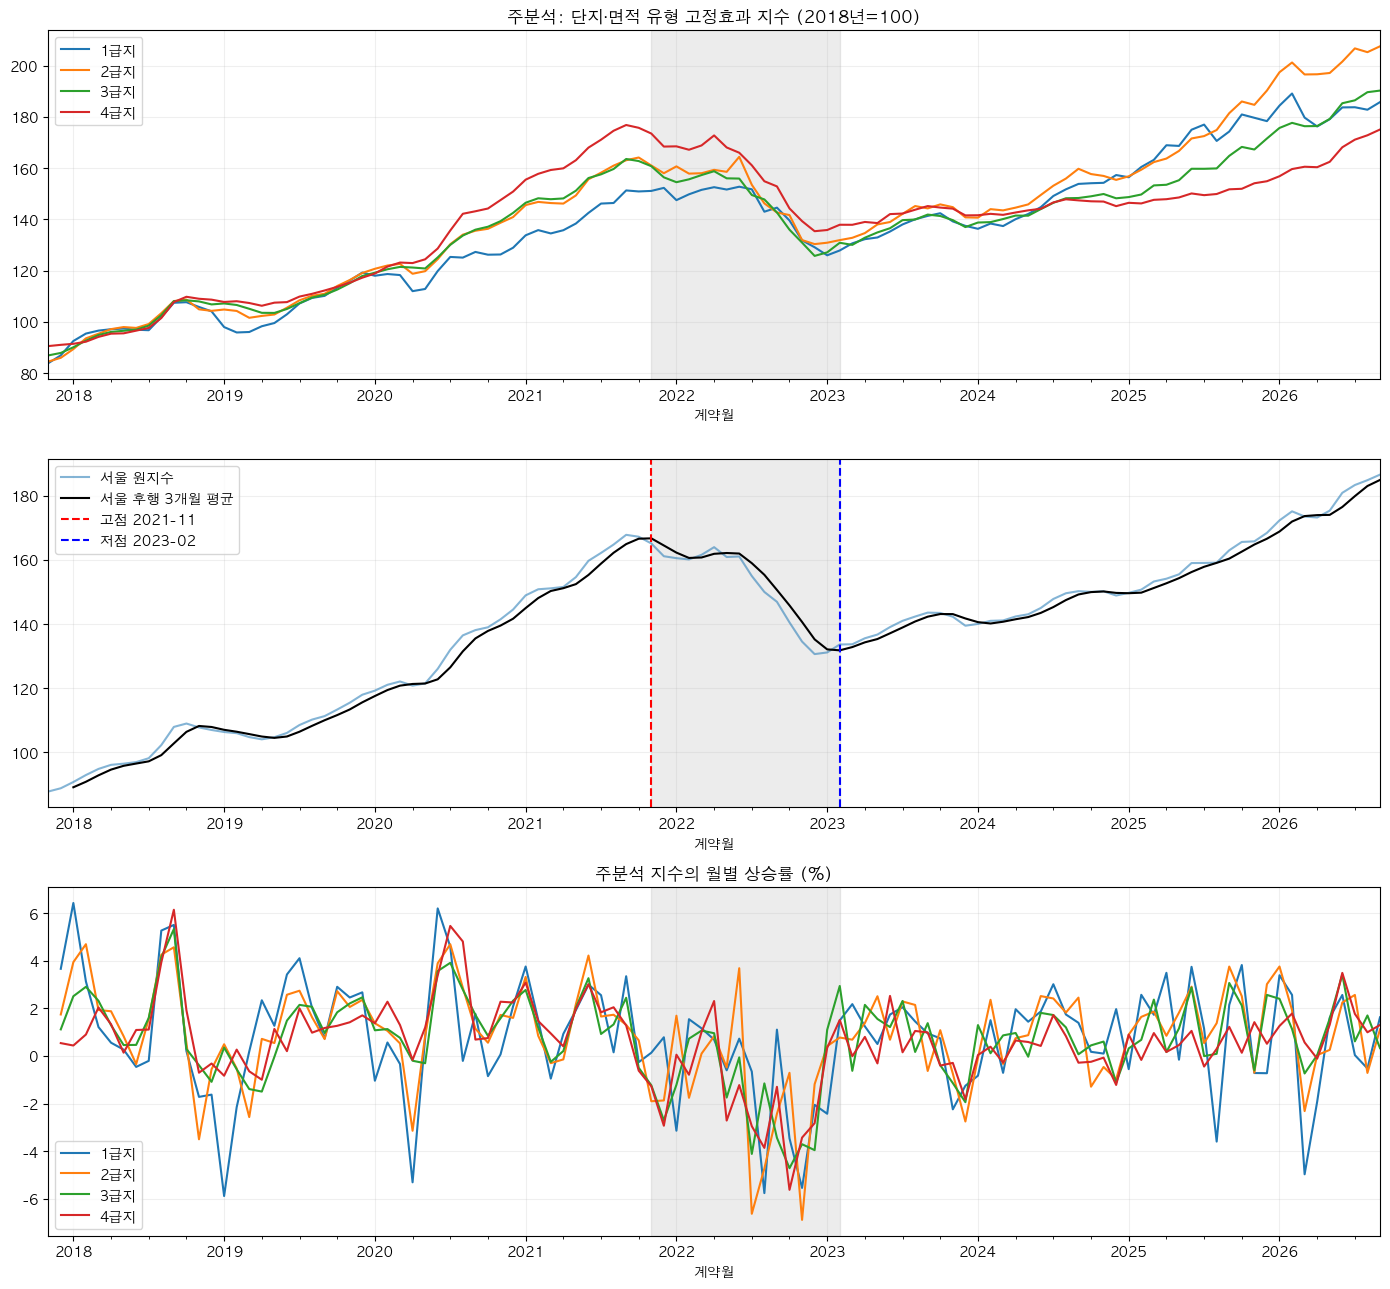

In [6]:
seoul=fe_gu.mean(axis=1)
seoul_smooth=seoul.rolling(3,min_periods=3).mean().dropna()
drawdown=seoul_smooth/seoul_smooth.cummax()-1
trough=drawdown.idxmin();peak=seoul_smooth.loc[:trough].idxmax()
assert peak<trough
# 가격 고저점은 후행 MA3 기준이며 사후적 구분. 월별 상승률의 소속은 종료월 기준으로 겹치지 않게 지정.
windows={'전체':(months[1],end),'고점이전':(months[1],peak),'하락국면':(peak+pd.offsets.MonthBegin(1),trough),'저점이후':(trough+pd.offsets.MonthBegin(1),end)}
phase_rows=[]
for name,(a,b) in windows.items():
    baseline=a-pd.offsets.MonthBegin(1)
    phase_rows.append({'국면':name,'상승률시작':a,'종료':b,'월수':len(pd.date_range(a,b,freq='MS')),
        '서울원지수변화_pct':(seoul.loc[b]/seoul.loc[baseline]-1)*100})
phases=pd.DataFrame(phase_rows)
print(f'서울 후행3개월 평균의 최대낙폭 고점: {peak:%Y-%m}, 저점: {trough:%Y-%m}, 낙폭: {drawdown.min()*100:.2f}%')
display(phases);save(phases,'market_phases');save(pd.DataFrame({'서울고정유형지수':seoul,'후행3개월평균':seoul_smooth}),'seoul_index')
fig,axes=plt.subplots(3,1,figsize=(14,13))
main.plot(ax=axes[0],title='주분석: 단지·면적 유형 고정효과 지수 (2018년=100)')
seoul.plot(ax=axes[1],label='서울 원지수',alpha=.55)
seoul_smooth.plot(ax=axes[1],label='서울 후행 3개월 평균',color='black')
axes[1].axvline(peak,color='red',linestyle='--',label=f'고점 {peak:%Y-%m}')
axes[1].axvline(trough,color='blue',linestyle='--',label=f'저점 {trough:%Y-%m}')
returns['주분석_고정유형4'].plot(ax=axes[2],title='주분석 지수의 월별 상승률 (%)')
for ax in axes:
    ax.axvspan(peak,trough,color='gray',alpha=.15);ax.grid(alpha=.2);ax.legend();ax.set_xlabel('계약월')
fig.tight_layout();fig.savefig(out/'indices_and_regimes.png',dpi=140,bbox_inches='tight');plt.show()


## ADF 및 12방향 Granger 공통 함수

In [7]:
# 양방향은 항상 같은 구간·같은 변환 사용. ADF 미통과 시 추가 1차분까지 허용하되 상승률 변화 검정임을 표시.
def longest(frame):
    ok=frame.notna().all(axis=1);block=(~ok).cumsum()
    if not ok.any():return frame.iloc[:0]
    chosen=block[ok].value_counts().idxmax()
    return frame.loc[ok & block.eq(chosen)]
def adf(s):
    maxlag=min(3,len(s)//2-2)
    if len(s)<10 or maxlag<0:return np.nan
    return adfuller(s,maxlag=maxlag,regression='c',autolag='AIC')[1]
adf_rows=[]
for spec in ['주분석_고정유형4','평균4_1개월보간']:
    for kind,table in [('가격지수',specs[spec]),('상승률',returns[spec])]:
        for tier in table:
            s=table[tier].dropna();adf_rows.append({'사양':spec,'계열':kind,'급지':tier,'월수':len(s),'ADF_p':adf(s)})
adf_table=pd.DataFrame(adf_rows).replace({'가격지수':'가격지수'})
display(adf_table);save(adf_table,'adf_full')
checks=[];skipped=[]
def run_tests(spec,period,a,b):
    frame=returns[spec].loc[a:b]
    rows=[];tiers=list(frame.columns)
    for i,x in enumerate(tiers):
        for y in tiers[i+1:]:
            pair=longest(frame[[x,y]])
            original_n=len(pair)
            if original_n<12:
                skipped.append({'사양':spec,'국면':period,'쌍':x+'↔'+y,'사유':'12개월 미만','월수':original_n});continue
            stationary=False
            for d in range(2):
                px,py=adf(pair[x]),adf(pair[y])
                checks.append({'사양':spec,'국면':period,'쌍':x+'↔'+y,'추가차분':d,'월수':len(pair),'ADF_x':px,'ADF_y':py})
                if px<.05 and py<.05:stationary=True;break
                if d==0:pair=pair.diff().dropna()
            if not stationary:
                skipped.append({'사양':spec,'국면':period,'쌍':x+'↔'+y,'사유':'ADF 미통과(추가1차분까지)','월수':len(pair)});continue
            for lag in range(1,MAX_LAG+1):
                if len(pair)-3*lag-1<8:
                    skipped.append({'사양':spec,'국면':period,'쌍':x+'↔'+y,'사유':f'차수{lag} 잔차자유도8 미만','월수':len(pair)});continue
                for cause,effect in [(x,y),(y,x)]:
                    with warnings.catch_warnings():
                        warnings.simplefilter('ignore',FutureWarning)
                        test=grangercausalitytests(pair[[effect,cause]],maxlag=[lag],verbose=False)[lag]
                    f,p,_,_=test[0]['ssr_ftest'];ols=test[1][1]
                    lb=acorr_ljungbox(ols.resid,lags=[min(6,max(1,len(ols.resid)//5))],return_df=True)['lb_pvalue'].iloc[0]
                    # HAC Wald joint test: overlapping MA and residual correlation sensitivity, same lag restrictions.
                    robust=ols.get_robustcov_results(cov_type='HAC',maxlags=3)
                    restriction=np.zeros((lag,len(ols.params)))
                    restriction[:,lag:2*lag]=np.eye(lag)
                    hacp=float(robust.f_test(restriction).pvalue)
                    rows.append({'사양':spec,'국면':period,'방향':cause+' → '+effect,'원인':cause,'대상':effect,'차수':lag,
                        '추가차분':d,'시작':pair.index.min(),'종료':pair.index.max(),'월수':len(pair),'F':f,'p':p,'HAC_p':hacp,'잔차LB_p':lb})
    return rows
allrows=[]
for period,(a,b) in windows.items():allrows+=run_tests('주분석_고정유형4',period,a,b)
for spec in specs:
    if spec!='주분석_고정유형4':allrows+=run_tests(spec,'전체',*windows['전체'])
results=pd.DataFrame(allrows)
# 전체 주분석 36개, 국면별 주분석 전체, 강건성 전체를 각각 별도 탐색 검정군으로 보정한다.
results['검정군']=np.where(results['사양'].eq('주분석_고정유형4'),np.where(results['국면'].eq('전체'),'주분석전체','주분석국면'),'강건성전체')
for _,group in results.groupby('검정군'):
    results.loc[group.index,'q']=multipletests(group['p'],method='fdr_bh')[1]
    results.loc[group.index,'HAC_q']=multipletests(group['HAC_p'],method='fdr_bh')[1]
results['유의']=results['q']<.05
results['HAC유의']=results['HAC_q']<.05
save(results,'granger_all');save(pd.DataFrame(checks),'pair_adf');save(pd.DataFrame(skipped),'skipped_tests')
main_results=results[results['검정군'].eq('주분석전체')]
display(main_results[['방향','차수','월수','추가차분','p','q','HAC_q','잔차LB_p']].round(5))
print('국면별 검정 개수/유의 개수')
display(results[results['사양'].eq('주분석_고정유형4')].groupby('국면').agg(검정수=('p','size'),유의수=('유의','sum'),HAC유의수=('HAC유의','sum')))
display(pd.DataFrame(skipped))


국면별 검정 개수/유의 개수


,사양,계열,급지,월수,ADF_p
0,주분석_고정유형4,가격지수,1급지,107,8.845207e-01
1,주분석_고정유형4,가격지수,2급지,107,9.163756e-01
2,주분석_고정유형4,가격지수,3급지,107,7.999321e-01
3,주분석_고정유형4,가격지수,4급지,107,5.164776e-01
4,주분석_고정유형4,상승률,1급지,106,5.607831e-10
5,주분석_고정유형4,상승률,2급지,106,3.447663e-09
6,주분석_고정유형4,상승률,3급지,106,1.527302e-06
7,주분석_고정유형4,상승률,4급지,106,1.610738e-05
8,평균4_1개월보간,가격지수,1급지,107,8.110587e-01
9,평균4_1개월보간,가격지수,2급지,107,9.101422e-01


,방향,차수,월수,추가차분,p,q,HAC_q,잔차LB_p
0,1급지 → 2급지,1,106,0,0.02485,0.04067,0.05150,0.34991
1,2급지 → 1급지,1,106,0,0.00258,0.00664,0.00259,0.03761
2,1급지 → 2급지,2,106,0,0.06465,0.08312,0.07005,0.53706
3,2급지 → 1급지,2,106,0,0.00080,0.00361,0.00052,0.39903
4,1급지 → 2급지,3,106,0,0.11761,0.14114,0.05895,0.90497
5,2급지 → 1급지,3,106,0,0.00252,0.00664,0.00056,0.51883
6,1급지 → 3급지,1,106,0,0.36344,0.38482,0.36511,0.95007
7,3급지 → 1급지,1,106,0,0.00001,0.00011,0.00056,0.00744
8,1급지 → 3급지,2,106,0,0.66523,0.68424,0.66783,0.94858
9,3급지 → 1급지,2,106,0,0.00000,0.00000,0.00000,0.05590


,검정수,유의수,HAC유의수
국면,,,
고점이전,36,0,8
저점이후,36,3,7
전체,36,26,23
하락국면,14,0,3


,사양,국면,쌍,사유,월수
0,주분석_고정유형4,하락국면,1급지↔2급지,차수3 잔차자유도8 미만,15
1,주분석_고정유형4,하락국면,1급지↔3급지,차수2 잔차자유도8 미만,14
2,주분석_고정유형4,하락국면,1급지↔3급지,차수3 잔차자유도8 미만,14
3,주분석_고정유형4,하락국면,1급지↔4급지,차수2 잔차자유도8 미만,14
4,주분석_고정유형4,하락국면,1급지↔4급지,차수3 잔차자유도8 미만,14
5,주분석_고정유형4,하락국면,2급지↔3급지,차수2 잔차자유도8 미만,14
6,주분석_고정유형4,하락국면,2급지↔3급지,차수3 잔차자유도8 미만,14
7,주분석_고정유형4,하락국면,2급지↔4급지,차수2 잔차자유도8 미만,14
8,주분석_고정유형4,하락국면,2급지↔4급지,차수3 잔차자유도8 미만,14
9,주분석_고정유형4,하락국면,3급지↔4급지,차수2 잔차자유도8 미만,14


## 양방향 요약 및 사양 비교

완료: 전체기간·국면별·강건성 결과 저장 /Users/jujihun/Desktop/dev/property-estimate/outputs/02_analysis


,사양,국면,쌍,고→저유의차수,저→고유의차수,판정,고→저HAC유의차수,저→고HAC유의차수
20,주분석_고정유형4,고점이전,1급지 ↔ 2급지,[],[],양방향 미검출,"[1, 2]",[]
21,주분석_고정유형4,고점이전,1급지 ↔ 3급지,[],[],양방향 미검출,[],[]
22,주분석_고정유형4,고점이전,1급지 ↔ 4급지,[],[],양방향 미검출,[],[3]
23,주분석_고정유형4,고점이전,2급지 ↔ 3급지,[],[],양방향 미검출,"[1, 2]","[2, 3]"
24,주분석_고정유형4,고점이전,2급지 ↔ 4급지,[],[],양방향 미검출,[3],[]
25,주분석_고정유형4,고점이전,3급지 ↔ 4급지,[],[],양방향 미검출,[],[]
26,주분석_고정유형4,저점이후,1급지 ↔ 2급지,[],[],양방향 미검출,[],[2]
27,주분석_고정유형4,저점이후,1급지 ↔ 3급지,[],"[1, 2, 3]",저→고만 검출,[],"[1, 2, 3]"
28,주분석_고정유형4,저점이후,1급지 ↔ 4급지,[],[],양방향 미검출,[],[]
29,주분석_고정유형4,저점이후,2급지 ↔ 3급지,[],[],양방향 미검출,[],"[2, 3]"


,사양,방향,차수,월수,p,q,HAC_q
30,주분석_고정유형4,3급지 → 4급지,1,106,0.000536,0.002756,0.007936
31,주분석_고정유형4,4급지 → 3급지,1,106,0.031377,0.046874,0.040354
32,주분석_고정유형4,3급지 → 4급지,2,106,0.001021,0.003675,0.010277
33,주분석_고정유형4,4급지 → 3급지,2,106,0.032551,0.046874,0.038015
34,주분석_고정유형4,3급지 → 4급지,3,106,0.000961,0.003675,0.016836
35,주분석_고정유형4,4급지 → 3급지,3,106,0.041875,0.055833,0.027252
152,평균4_1개월보간,3급지 → 4급지,1,106,0.000139,0.001260,0.003436
153,평균4_1개월보간,4급지 → 3급지,1,106,0.717587,0.813060,0.691857
154,평균4_1개월보간,3급지 → 4급지,2,106,0.001017,0.005065,0.012326
155,평균4_1개월보간,4급지 → 3급지,2,106,0.494722,0.621936,0.371726


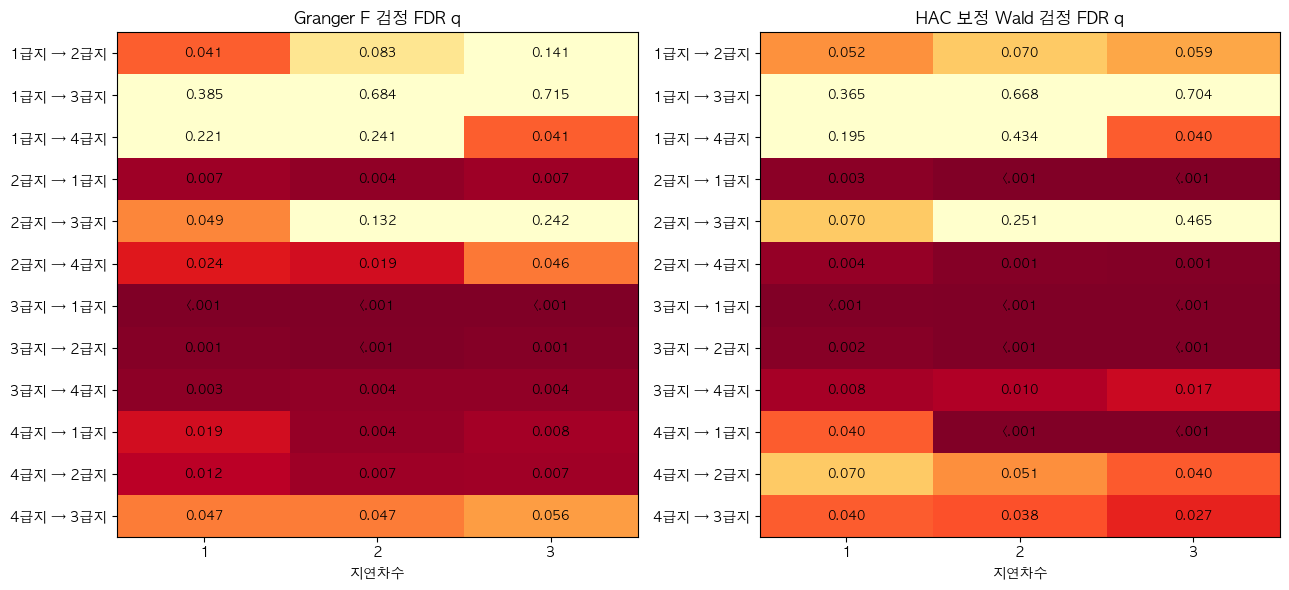

In [8]:
pair_rows=[]
for (spec,period),group in results.groupby(['사양','국면']):
    tiers=sorted(set(group['원인'])|set(group['대상']))
    for i,x in enumerate(tiers):
        for y in tiers[i+1:]:
            forward=group[group['원인'].eq(x)&group['대상'].eq(y)]
            reverse=group[group['원인'].eq(y)&group['대상'].eq(x)]
            fs=forward.loc[forward['유의'],'차수'].tolist();rs=reverse.loc[reverse['유의'],'차수'].tolist()
            pair_rows.append({'사양':spec,'국면':period,'쌍':x+' ↔ '+y,'고→저유의차수':str(fs),'저→고유의차수':str(rs),
                '판정':'양방향' if fs and rs else '고→저만 검출' if fs else '저→고만 검출' if rs else '양방향 미검출',
                '고→저HAC유의차수':str(forward.loc[forward['HAC유의'],'차수'].tolist()),'저→고HAC유의차수':str(reverse.loc[reverse['HAC유의'],'차수'].tolist())})
summary=pd.DataFrame(pair_rows)
display(summary[summary['사양'].eq('주분석_고정유형4')]);save(summary,'direction_summary')
# 기존 3→4를 전체 기간에서 재검정한 결과를 우선 출력
focus=results[(results['사양'].isin(['주분석_고정유형4','평균4_1개월보간','평균4_최소1건']))&results['국면'].eq('전체')&results['방향'].isin(['3급지 → 4급지','4급지 → 3급지'])]
display(focus[['사양','방향','차수','월수','p','q','HAC_q']].round(6));save(focus,'priority_3_4')
fig,axes=plt.subplots(1,2,figsize=(13,6))
for ax,column,title in zip(axes,['q','HAC_q'],['Granger F 검정 FDR q','HAC 보정 Wald 검정 FDR q']):
    table=main_results.pivot(index='방향',columns='차수',values=column)
    im=ax.imshow(table.to_numpy(),vmin=0,vmax=.1,cmap='YlOrRd_r',aspect='auto')
    ax.set_yticks(range(len(table)),table.index);ax.set_xticks(range(3),['1','2','3']);ax.set_xlabel('지연차수');ax.set_title(title)
    for r in range(len(table)):
        for c in range(3):ax.text(c,r,'<.001' if table.iloc[r,c]<.001 else f'{table.iloc[r,c]:.3f}',ha='center',va='center',fontsize=9)
fig.tight_layout();fig.savefig(out/'bidirectional_tests.png',dpi=140,bbox_inches='tight');plt.show()
print('완료: 전체기간·국면별·강건성 결과 저장',out)


## 방법 참고
- [statsmodels Granger API](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.grangercausalitytests.html): 입력 열은 대상, 원인 순서이며 두 번째 시계열의 추가 예측정보를 공동 검정한다.
- [statsmodels ADF API](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html): 단위근 귀무가설 검정.
- [Eurostat 주택가격지수 기술 매뉴얼](https://ec.europa.eu/eurostat/documents/7590317/0/Technical-Manual-OOH-HPI-2017/): 시간 더미의 지수화 접근을 참고했다. 본 노트북은 공식 지수 재현이 아닌 단지·면적 유형 고정효과를 사용한 탐색용 구현이다.
